# 1. Adatok és volatilitásmértékek – kézi ellenőrzés

Ez a notebook azt mutatja meg, hogy a projekt **napi volatilitásmértékei** és **input táblái** helyesek-e.
Minden lépést a notebook *kézzel*, egyszerű numpy-képletekkel újraszámol, és összeveti a projekt tárolt eredményével.

**Futtatás:** felül *Run All*, vagy cellánként **Shift+Enter**. A beállításokat (pl. a vizsgált napot) szabadon át lehet írni.
A notebook semmit nem ír felül.

| Lépés | Mit ellenőrzünk | A projekt kódja |
|---|---|---|
| 1 | RV, BPV, ugrásteszt, Parkinson, Garman–Klass egy kiválasztott napra | `src/measures.py` |
| 2 | Az ugrásos napok a teljes mintán | `data/processed/measures_daily.csv` |
| 3 | A HAR-tagok és a cél (holnapi szórás) az input táblában | `src/inputs.py` |

In [1]:
# A projekt gyökerének megkeresése és a közös motor (src/) betöltése
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("projekt:", ROOT)

projekt: C:\Users\Tamás\Thesis_V3


## 1. Egy nap mértékei kézzel

Válassz egy kereskedési napot (2009-09-28 és 2026-07-10 között). A 2020-04-13 egy erős ugrásos nap, a 2019-06-12 egy átlagos nap.
A képletek magyarázata: `docs/13_ugrasteszt_magyarazat.pdf`.

In [2]:
from config import PROCESSED, WTI_PIPELINE

NAP = "2020-04-13"          # <- ide bármely kereskedési nap írható

bars = pd.read_parquet(WTI_PIPELINE / "wti_5min_sessions.parquet")
nap = bars[bars["trading_day"] == NAP]
print(f"{NAP}: {len(nap)} db 5 perces bár, {nap['bar_start'].min()} – {nap['bar_start'].max()}")
nap[["bar_start", "open", "high", "low", "close", "r"]].head()

2020-04-13: 276 db 5 perces bár, 2020-04-12 18:00:00-04:00 – 2020-04-13 16:55:00-04:00


,bar_start,open,high,low,close,r
744442,2020-04-12 18:00:00-04:00,24.60,24.74,22.20,22.62,-0.083912
744443,2020-04-12 18:05:00-04:00,22.62,22.95,22.37,22.60,-0.000885
744444,2020-04-12 18:10:00-04:00,22.61,22.67,22.03,22.34,-0.011571
744445,2020-04-12 18:15:00-04:00,22.35,22.51,22.05,22.28,-0.002689
744446,2020-04-12 18:20:00-04:00,22.26,22.53,22.23,22.48,0.008937


In [3]:
from math import gamma
from scipy.stats import norm

# --- Kézi számítás, közvetlenül a képletekből (src/measures.py nélkül) ---------------------------
r = nap["r"].to_numpy()                                   # 5 perces log-hozamok
n = len(r)
RV = np.sum(r ** 2)                                        # realizált variancia
BPV = (np.pi / 2) * n / (n - 1) * np.sum(np.abs(r[1:]) * np.abs(r[:-1]))      # bipower variation
mu43 = 2 ** (2 / 3) * gamma(7 / 6) / gamma(1 / 2)                              # E|Z|^(4/3)
TPQ = n * mu43 ** -3 * n / (n - 2) * np.sum((np.abs(r[2:]) * np.abs(r[1:-1]) * np.abs(r[:-2])) ** (4 / 3))
z = np.sqrt(n) * ((RV - BPV) / RV) / np.sqrt((np.pi ** 2 / 4 + np.pi - 5) * max(1, TPQ / BPV ** 2))
J = RV - BPV if z > norm.ppf(0.999) else 0.0              # ugrás, ha z > 3,09
hl = np.log(nap["high"] / nap["low"]).to_numpy()
co = np.log(nap["close"] / nap["open"]).to_numpy()
PK = np.sum(hl ** 2) / (4 * np.log(2))                                         # Parkinson
GK = np.sum(0.5 * hl ** 2 - (2 * np.log(2) - 1) * co ** 2)                     # Garman–Klass

kezzel = pd.Series({"RV": RV, "BPV": BPV, "J": J, "C": RV - J, "jump_z": z, "Parkinson": PK, "Garman_Klass": GK})

# --- Összevetés a projekt tárolt eredményével ------------------------------------------------------
meas = pd.read_csv(PROCESSED / "measures_daily.csv", index_col=0, parse_dates=True)
if pd.Timestamp(NAP) not in meas.index:
    print("Ez a nap nem érvényes kereskedési nap (pl. ünnep vagy hiányos session), ezért nincs a mintában.")
else:
    tarolt = meas.loc[NAP, kezzel.index]
    print(f"z = {z:.2f}  ->  {'UGRÁSOS nap' if J > 0 else 'nincs szignifikáns ugrás'} (küszöb: {norm.ppf(0.999):.2f})")
    display(pd.DataFrame({"kézzel": kezzel, "projekt (measures_daily.csv)": tarolt,
                          "relatív eltérés": (kezzel - tarolt) / tarolt.where(tarolt != 0, 1)}))

z = 10.28  ->  UGRÁSOS nap (küszöb: 3.09)


,kézzel,projekt (measures_daily.csv),relatív eltérés
RV,0.013787,0.013787,4.026434e-15
BPV,0.006224,0.006224,1.184514e-14
J,0.007563,0.007563,1.078103e-14
C,0.006224,0.006224,1.184514e-14
jump_z,10.276927,10.276927,-1.728490e-16
Parkinson,0.011699,0.011699,1.037989e-15
Garman_Klass,0.010880,0.010880,7.334514e-15


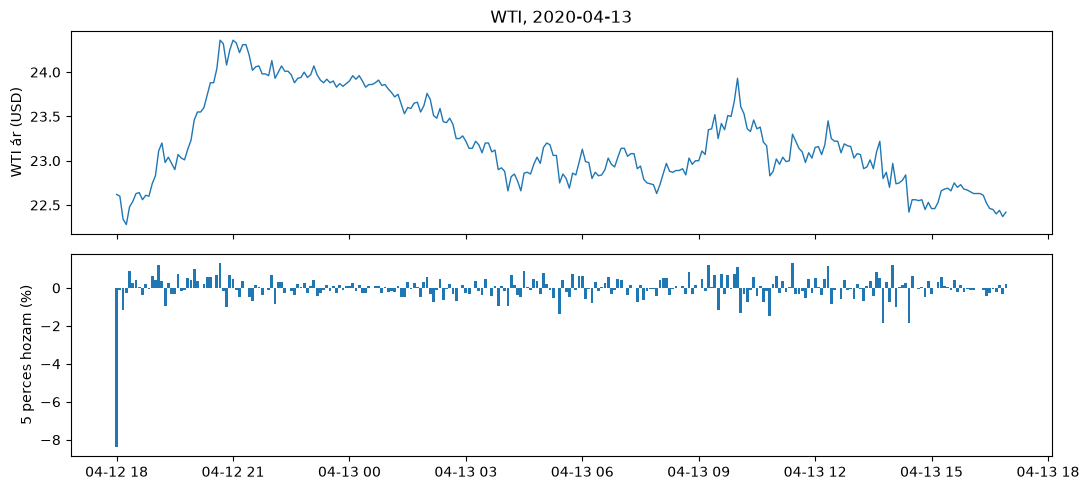

In [4]:
# A nap árfolyama és az 5 perces hozamok: az ugrás egyetlen nagy hozamként látszik
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(nap["bar_start"], nap["close"], lw=1)
ax[0].set_ylabel("WTI ár (USD)")
ax[0].set_title(f"WTI, {NAP}")
ax[1].bar(nap["bar_start"], nap["r"] * 100, width=0.003)
ax[1].set_ylabel("5 perces hozam (%)")
plt.tight_layout()
plt.show()

## 2. Ugrásos napok a teljes mintán

In [5]:
ugras = meas["J"] > 0
print(f"érvényes napok: {len(meas)}  ({meas.index.min().date()} – {meas.index.max().date()})")
print(f"ugrásos napok:  {ugras.sum()} ({ugras.mean():.1%})")
print(f"az ugrás aránya az RV-ben ugrásos napokon (medián): {(meas.J / meas.RV)[ugras].median():.1%}")
print(f"az ugrások aránya a teljes RV-ben: {meas.J.sum() / meas.RV.sum():.1%}")
print("\nA 10 legerősebb ugrásjelzés:")
meas.assign(J_arany=meas.J / meas.RV).sort_values("jump_z", ascending=False).head(10)[["RV", "BPV", "J", "J_arany", "jump_z"]]

érvényes napok: 4168  (2009-09-28 – 2026-07-10)
ugrásos napok:  473 (11.3%)
az ugrás aránya az RV-ben ugrásos napokon (medián): 23.6%
az ugrások aránya a teljes RV-ben: 3.2%

A 10 legerősebb ugrásjelzés:


,RV,BPV,J,J_arany,jump_z
trading_day,,,,,
2011-02-17,0.001255,0.000209,0.001046,0.833164,12.824382
2016-12-16,0.000729,0.000312,0.000418,0.572751,10.811831
2020-04-13,0.013787,0.006224,0.007563,0.548540,10.276927
2017-03-17,0.000219,0.000108,0.000111,0.505546,9.371450
2018-05-23,0.000192,0.000080,0.000112,0.584544,9.072694
2017-01-25,0.000285,0.000131,0.000154,0.539130,8.771739
2016-10-18,0.000265,0.000145,0.000120,0.452338,8.422046
2025-11-25,0.000574,0.000299,0.000276,0.480185,8.182358
2018-07-02,0.000311,0.000195,0.000116,0.372802,7.874824


## 3. Az input tábla ellenőrzése

Egy input tábla sora egy nap. A `har_d`, `har_w`, `har_m` a mérték utolsó 1, 5 és 22 érvényes napjának átlagos varianciájából
vont gyök (napi szórás), transzformálva. A cél (`y`) a **következő** kereskedési nap szórása (√RV), ugyanígy transzformálva.
Itt kézzel újraszámoljuk őket egy napra. (Az RV_CJ mérték C/J tagokat használ, ezért itt az RV, a Parkinson vagy a Garman_Klass választható.)

In [6]:
from config import INPUT

MERTEK = "RV"               # RV, Parkinson vagy Garman_Klass
TRANSZF = "Log"             # Log vagy QuarticRoot
DATUM = "2020-04-13"        # a közös mintán belüli nap (2015-06-25 – 2026-07-09)

T = {"Log": np.log, "QuarticRoot": np.sqrt}[TRANSZF]
inp = pd.read_csv(INPUT / TRANSZF / f"{MERTEK}.csv", index_col="date", parse_dates=True)

v = meas[MERTEK].loc[:DATUM]                       # csak a DATUM-ig ismert napok
kov_nap = meas.index[meas.index.get_loc(pd.Timestamp(DATUM)) + 1]
kezzel = pd.Series({
    "har_d": T(np.sqrt(v.tail(1).mean())),
    "har_w": T(np.sqrt(v.tail(5).mean())),
    "har_m": T(np.sqrt(v.tail(22).mean())),
    "sigma_next": np.sqrt(meas.loc[kov_nap, "RV"]),
    "y": T(np.sqrt(meas.loc[kov_nap, "RV"])),
})
print(f"a cél napja: {kov_nap.date()} (a {DATUM} utáni kereskedési nap)")
pd.DataFrame({"kézzel": kezzel, "input tábla": inp.loc[DATUM, kezzel.index], "eltérés": kezzel - inp.loc[DATUM, kezzel.index]})

a cél napja: 2020-04-14 (a 2020-04-13 utáni kereskedési nap)


,kézzel,input tábla,eltérés
har_d,-2.142026,-2.142026,0.000000e+00
har_w,-2.309038,-2.309038,0.000000e+00
har_m,-2.309595,-2.309595,-4.440892e-16
sigma_next,0.062826,0.062826,-6.106227e-16
y,-2.767385,-2.767385,-9.769963e-15


In [7]:
# Az input tábla összes oszlopa egy napra: L1 (HAR) + L2 (makró) + L3 (cross-asset) + L4 (hírek)
print(f"{len(inp)} nap: {inp.index.min().date()} – {inp.index.max().date()}")
inp.loc[DATUM].to_frame("érték")

2591 nap: 2015-06-25 – 2026-07-09


,érték
sigma_next,0.062826
y,-2.767385
har_d,-2.142026
har_w,-2.309038
har_m,-2.309595
ovx,-2.629834
vix,-3.652175
sp500,-4.314098
usd,-5.074130
copper,-4.838414


**Az időzítés (nincs jövőbeli adat)** részletes, automatikus tesztjei a `tests/test_data.py` fájlban vannak;
a 4. notebook végén mind a 21 teszt lefuttatható.